# Hyperparameter Tuning for DQN with Ray Tune

*Notebook 4 of the series: value functions → Q-learning → DQN → **tuning DQN with Ray Tune***

In the DQN notebook we tuned hyperparameters with Optuna, one trial at a time. [Ray Tune](https://docs.ray.io/en/latest/tune/index.html)
solves the same problem, but it is built for **running many trials in parallel**, on all your CPU cores, your GPUs,
or a whole cluster. It also offers **schedulers** that can stop bad trials early, or even change hyperparameters
*during* training.

## Ray Tune in six concepts

| Concept | Meaning in this notebook |
|---|---|
| **Trainable** | a function `dqn_trainable(config)` that trains DQN and calls `tune.report(metrics)` every 10k steps |
| **Param space** | the search space: `tune.loguniform(...)`, `tune.choice([...])`, ... |
| **Search algorithm** | *which* configurations to try: random sampling (the default), or Optuna's TPE plugged into Ray |
| **Scheduler** | *how long* each trial runs: ASHA stops bad trials early, PBT mutates good trials while they run |
| **Resources** | how much hardware one trial gets, e.g. `{"cpu": 1}` or `{"cpu": 2, "gpu": 0.5}` |
| **ResultGrid** | what `tuner.fit()` returns: all trials, their metrics and the best configuration |

## Three experiments on CartPole
1. **Random search + ASHA:** a strong, simple baseline that runs fully in parallel.
2. **Optuna (TPE) + ASHA:** Bayesian-style search inside Ray, the best of both libraries.
3. **Population Based Training (PBT):** a population of agents that copy the best members and mutate their
   hyperparameters during training. It is popular in RL because the best learning rate early on is often not the best later.

At the end, the winners of all three are **validated on unseen seeds** against the default settings, again run in parallel with Ray.

In [36]:
# !pip install "ray[tune]" optuna gymnasium torch matplotlib pandas
import os
import random
import tempfile
import time
from collections import defaultdict
from dataclasses import dataclass, replace, asdict

import gymnasium as gym
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim

import ray
from ray import tune
from ray.tune.schedulers import ASHAScheduler, PopulationBasedTraining
from ray.tune.search import ConcurrencyLimiter
from ray.tune.search.optuna import OptunaSearch
import optuna

print("ray", ray.__version__, "| optuna", optuna.__version__, "| torch", torch.__version__,
      "| gymnasium", gym.__version__)

os.environ["TUNE_WARN_EXCESSIVE_EXPERIMENT_CHECKPOINT_SYNC_THRESHOLD_S"] = "0"

ray 2.59.0 | optuna 5.0.0 | torch 2.14.1 | gymnasium 1.4.0


## 1. The DQN components

These are the same building blocks as the DQN notebook (CleanRL-style), copied here so this notebook is self-contained.

**One important change:** the training loop is now a `DQNAgent` *class* that can train for *n* more steps, then pause.
Its full state (networks, optimizer, replay buffer, step counter, RNG states) can be saved and restored. Ray Tune needs
this for two reasons:
- to **report** metrics regularly while training continues, which ASHA uses to stop bad trials, and
- for **checkpoints**: PBT copies the network *and* replay buffer of a good agent into a weaker one, and Ray can resume
  trials after a crash.

In [37]:
@dataclass
class Args:
    env_id: str = "CartPole-v1"
    seed: int = 1
    total_timesteps: int = 100_000
    learning_rate: float = 2.5e-4
    buffer_size: int = 10_000
    gamma: float = 0.99
    tau: float = 1.0
    target_network_frequency: int = 500
    batch_size: int = 128
    start_e: float = 1.0
    end_e: float = 0.05
    exploration_fraction: float = 0.5
    learning_starts: int = 10_000
    train_frequency: int = 10


class MLPQNetwork(nn.Module):
    def __init__(self, env):
        super().__init__()
        n_obs = int(np.prod(env.observation_space.shape))
        self.network = nn.Sequential(
            nn.Linear(n_obs, 120), nn.ReLU(),
            nn.Linear(120, 84), nn.ReLU(),
            nn.Linear(84, env.action_space.n),
        )

    def forward(self, x):
        return self.network(x)


class ReplayBuffer:
    def __init__(self, size, obs_shape, obs_dtype):
        self.size = size
        self.obs = np.zeros((size, *obs_shape), dtype=obs_dtype)
        self.next_obs = np.zeros((size, *obs_shape), dtype=obs_dtype)
        self.actions = np.zeros((size, 1), dtype=np.int64)
        self.rewards = np.zeros(size, dtype=np.float32)
        self.dones = np.zeros(size, dtype=np.float32)
        self.pos, self.full = 0, False

    def add(self, obs, next_obs, action, reward, terminated):
        self.obs[self.pos], self.next_obs[self.pos] = obs, next_obs
        self.actions[self.pos], self.rewards[self.pos], self.dones[self.pos] = action, reward, terminated
        self.pos = (self.pos + 1) % self.size
        self.full = self.full or self.pos == 0

    def sample(self, batch_size):
        idx = np.random.randint(0, self.size if self.full else self.pos, size=batch_size)
        t = torch.as_tensor
        return (t(self.obs[idx]).float(), t(self.actions[idx]), t(self.next_obs[idx]).float(),
                t(self.rewards[idx]), t(self.dones[idx]))

    # for checkpointing
    def state_dict(self):
        return dict(vars(self))

    def load_state_dict(self, state):
        vars(self).update(state)


def linear_schedule(start_e, end_e, duration, t):
    slope = (end_e - start_e) / duration
    return max(slope * t + start_e, end_e)


def evaluate(q_network, env_id, episodes=10, seed=10_000):
    '''Mean return of the greedy policy.'''
    env = gym.make(env_id)
    returns = []
    for ep in range(episodes):
        obs, _ = env.reset(seed=seed + ep)
        done, G = False, 0.0
        while not done:
            with torch.no_grad():
                action = int(q_network(torch.as_tensor(obs).float().unsqueeze(0)).argmax())
            obs, r, terminated, truncated, _ = env.step(action)
            G += r
            done = terminated or truncated
        returns.append(G)
    env.close()
    return float(np.mean(returns))

In [38]:
class DQNAgent:
    '''CleanRL-style DQN that can train in chunks, change hyperparameters, and save or restore its full state.'''

    def __init__(self, args: Args):
        self.args = args
        random.seed(args.seed); np.random.seed(args.seed); torch.manual_seed(args.seed)

        self.env = gym.wrappers.RecordEpisodeStatistics(gym.make(args.env_id))
        self.q_network = MLPQNetwork(self.env)
        self.target_network = MLPQNetwork(self.env)
        self.target_network.load_state_dict(self.q_network.state_dict())
        self.optimizer = optim.Adam(self.q_network.parameters(), lr=args.learning_rate)
        self.rb = ReplayBuffer(args.buffer_size, self.env.observation_space.shape, self.env.observation_space.dtype)

        self.env.action_space.seed(args.seed)
        self.obs, _ = self.env.reset(seed=args.seed)
        self.global_step = 0
        self.log = defaultdict(list)

    # ---------------------------------------------------------------- hyperparameters
    def set_hyperparams(self, **changes):
        '''Change hyperparameters mid-training (used by PBT). Only call with fields that can change.'''
        self.args = replace(self.args, **changes)
        for group in self.optimizer.param_groups:
            group["lr"] = self.args.learning_rate

    @property
    def epsilon(self):
        a = self.args
        return linear_schedule(a.start_e, a.end_e, a.exploration_fraction * a.total_timesteps, self.global_step)

    # ---------------------------------------------------------------- training
    def train_steps(self, n_steps):
        a = self.args
        for _ in range(n_steps):
            if random.random() < self.epsilon:
                action = self.env.action_space.sample()
            else:
                with torch.no_grad():
                    action = int(self.q_network(torch.as_tensor(self.obs).float().unsqueeze(0)).argmax())

            next_obs, reward, terminated, truncated, info = self.env.step(action)
            self.rb.add(self.obs, next_obs, action, reward, terminated)
            self.obs = next_obs
            if terminated or truncated:
                if "episode" in info:
                    self.log["episode_return"].append(float(info["episode"]["r"]))
                self.obs, _ = self.env.reset()

            if self.global_step > a.learning_starts:
                if self.global_step % a.train_frequency == 0:
                    b_obs, b_act, b_next, b_rew, b_done = self.rb.sample(a.batch_size)
                    with torch.no_grad():
                        target_max, _ = self.target_network(b_next).max(dim=1)
                        td_target = b_rew + a.gamma * target_max * (1 - b_done)
                    old_val = self.q_network(b_obs).gather(1, b_act).squeeze(1)
                    loss = F.mse_loss(td_target, old_val)
                    self.optimizer.zero_grad(); loss.backward(); self.optimizer.step()
                    self.log["td_loss"].append(loss.item())
                    self.log["q_value"].append(old_val.mean().item())

                if self.global_step % a.target_network_frequency == 0:
                    for tp, qp in zip(self.target_network.parameters(), self.q_network.parameters()):
                        tp.data.copy_(a.tau * qp.data + (1.0 - a.tau) * tp.data)
            self.global_step += 1

    def metrics(self, eval_episodes):
        recent = lambda k, n: float(np.mean(self.log[k][-n:])) if self.log[k] else float("nan")
        return {
            "global_step": self.global_step,
            "eval_return": evaluate(self.q_network, self.args.env_id, episodes=eval_episodes),
            "train_return": recent("episode_return", 20),
            "td_loss": recent("td_loss", 100),
            "q_value": recent("q_value", 100),
            "epsilon": self.epsilon,
            # log the *current* hyperparameters too, so PBT schedules can be plotted later
            "learning_rate": self.args.learning_rate,
            "target_network_frequency": self.args.target_network_frequency,
            "train_frequency": self.args.train_frequency,
            "batch_size": self.args.batch_size,
            "gamma": self.args.gamma,
        }

    # ---------------------------------------------------------------- checkpointing
    def state_dict(self):
        return {
            "q_network": self.q_network.state_dict(),
            "target_network": self.target_network.state_dict(),
            "optimizer": self.optimizer.state_dict(),
            "replay_buffer": self.rb.state_dict(),
            "global_step": self.global_step,
            "log": dict(self.log),
            "rng": (random.getstate(), np.random.get_state(), torch.get_rng_state()),
        }

    def load_state_dict(self, state):
        self.q_network.load_state_dict(state["q_network"])
        self.target_network.load_state_dict(state["target_network"])
        self.optimizer.load_state_dict(state["optimizer"])
        self.rb.load_state_dict(state["replay_buffer"])
        self.global_step = state["global_step"]
        self.log = defaultdict(list, state["log"])
        random.setstate(state["rng"][0]); np.random.set_state(state["rng"][1]); torch.set_rng_state(state["rng"][2])
        self.set_hyperparams()           # optimizer.load_state_dict restored the OLD lr; re-apply the current one
        self.obs, _ = self.env.reset()   # the env itself can't be checkpointed: start a fresh episode

Quick local check before involving Ray: train 20k steps and look at the metrics.

In [39]:
agent = DQNAgent(Args(total_timesteps=20_000, learning_starts=2_000))
t0 = time.time()
agent.train_steps(20_000)
print(f"{20_000 / (time.time() - t0):.0f} steps/s")
agent.metrics(eval_episodes=5)

20134 steps/s


{'global_step': 20000,
 'eval_return': 274.8,
 'train_return': 169.65,
 'td_loss': 5.226340652555227,
 'q_value': 26.361797332763672,
 'epsilon': 0.05,
 'learning_rate': 0.00025,
 'target_network_frequency': 500,
 'train_frequency': 10,
 'batch_size': 128,
 'gamma': 0.99}

## 2. The trainable

This is the function Ray runs once per trial, in its own worker process. It:
1. builds `Args` from the defaults plus the sampled `config`,
2. **restores from a checkpoint** if Ray provides one (PBT exploit, or a crash recovery),
3. trains in chunks of `REPORT_EVERY` steps, and after each chunk calls `tune.report(metrics)`, optionally
   with a checkpoint.

After every `tune.report`, the scheduler decides whether the trial continues, is stopped (ASHA), or is
replaced by a copy of a better trial (PBT).

`torch.set_num_threads(1)` matters. Without it, every trial would try to use all cores, and parallel trials would
slow each other down.

In [40]:
BASE_ARGS = Args()
TUNABLE = {f for f in asdict(BASE_ARGS) if f != "env_id"}   # config keys that map onto Args fields

REPORT_EVERY = 10_000        # steps between reports: ASHA and PBT make decisions at these points
EVAL_EPISODES = 5            # greedy episodes per report (cheap, a bit noisy)
FINAL_EVAL_EPISODES = 20     # more episodes at the very end of a trial


def dqn_trainable(config, checkpoint_every=None):
    '''checkpoint_every: save a checkpoint every N steps (PBT needs this); None = never checkpoint.'''
    torch.set_num_threads(1)
    args = replace(BASE_ARGS, **{k: v for k, v in config.items() if k in TUNABLE})
    agent = DQNAgent(args)

    checkpoint = tune.get_checkpoint()
    if checkpoint:
        with checkpoint.as_directory() as ckpt_dir:
            agent.load_state_dict(torch.load(os.path.join(ckpt_dir, "agent.pt"), weights_only=False))

    while agent.global_step < args.total_timesteps:
        agent.train_steps(min(REPORT_EVERY, args.total_timesteps - agent.global_step))
        last = agent.global_step >= args.total_timesteps
        metrics = agent.metrics(FINAL_EVAL_EPISODES if last else EVAL_EPISODES)

        if checkpoint_every and (agent.global_step % checkpoint_every == 0 or last):
            with tempfile.TemporaryDirectory() as tmp:
                torch.save(agent.state_dict(), os.path.join(tmp, "agent.pt"))
                tune.report(metrics, checkpoint=tune.Checkpoint.from_directory(tmp))
        else:
            tune.report(metrics)

## 3. Start Ray and define the search space

`ray.init()` starts a local Ray "cluster" on your machine and uses all CPU cores by default.
Each trial requests 1 CPU, so on an 8-core machine 8 trials run at the same time.
Results are written to `STORAGE_PATH`, so experiments can be inspected or **resumed** later (section 8).

The search space is the same as in the Optuna part of the DQN notebook, written in Ray's syntax.

In [41]:
ray.init(ignore_reinit_error=True)        # on a cluster: ray.init(address="auto")
N_CPUS = int(ray.cluster_resources().get("CPU", 1))
print("CPUs available to Ray:", N_CPUS)

STORAGE_PATH = os.path.abspath("ray_results")   # must be an absolute path (or s3://..., gs://...)
TRIAL_STEPS = 100_000
SEED = 1000                                      # same training seed for all search trials (fair comparison)

search_space = {
    "total_timesteps": TRIAL_STEPS,
    "seed": SEED,
    "learning_rate": tune.loguniform(1e-4, 3e-3),
    "batch_size": tune.choice([32, 64, 128, 256]),
    "buffer_size": tune.choice([10_000, 50_000, 100_000]),
    "target_network_frequency": tune.choice([100, 250, 500, 1000, 2000]),
    "gamma": tune.choice([0.95, 0.98, 0.99, 0.995]),
    "exploration_fraction": tune.uniform(0.05, 0.5),
    "end_e": tune.uniform(0.01, 0.1),
    "learning_starts": tune.choice([1_000, 5_000, 10_000]),
    "train_frequency": tune.choice([1, 4, 10]),
}

trainable = tune.with_resources(dqn_trainable, {"cpu": 1})   # add "gpu": 0.25 to share a GPU between 4 trials

2026-10-15 10:19:56,506	INFO worker.py:2033 -- Started a local Ray instance.


CPUs available to Ray: 15


### Helpers for looking at results

In [42]:
def finished_trials(results, steps=TRIAL_STEPS):
    '''One row per trial that ran the full budget (trials stopped early by ASHA are excluded).'''
    df = results.get_dataframe()
    df = df[df["global_step"] >= steps].sort_values("eval_return", ascending=False)
    keep = ["eval_return", "train_return", "global_step"] + [c for c in df.columns if c.startswith("config/")]
    out = df[keep].copy()
    out.columns = [c.replace("config/", "") for c in out.columns]
    return out.drop(columns=["total_timesteps", "seed"], errors="ignore").reset_index(drop=True)


def best_config(results, steps=TRIAL_STEPS):
    best = finished_trials(results, steps).iloc[0]
    # pandas upcasts a mixed int/float row to float -> cast back to each field's type in Args
    return {k: type(getattr(BASE_ARGS, k))(v) for k, v in best.items() if k in search_space}


def plot_curves(results, title, metric="eval_return"):
    best_cfg = best_config(results)
    plt.figure(figsize=(9, 5))
    for r in results:
        df = r.metrics_dataframe
        if df is None or metric not in df:
            continue
        is_best = all(r.config.get(k) == v for k, v in best_cfg.items())
        plt.plot(df["global_step"], df[metric], color="tab:green" if is_best else "tab:gray",
                 alpha=1.0 if is_best else 0.35, lw=2.5 if is_best else 1, zorder=3 if is_best else 1)
    plt.xlabel("global step"); plt.ylabel(metric); plt.title(f"{title} (green = best finished trial)")
    plt.grid(alpha=.3); plt.show()


def describe(results, name):
    n_err = results.num_errors
    finished = finished_trials(results)
    print(f"{name}: {len(results)} trials | {len(finished)} ran the full budget | {n_err} errors")
    print("best config:", best_config(results))
    return finished.head(10)

## 4. Experiment 1: random search + ASHA

**ASHA** (Asynchronous Successive Halving) works in "rungs". At `grace_period` steps it compares trials and keeps
only the best 1/`reduction_factor`. At the next rung, `grace_period × reduction_factor`, it filters again, and so on.
Here the rungs are at 30k and 90k steps, and only about 1 in 3 trials survives each rung.
Bad configurations are killed early, so we can afford many more samples for the same compute.
It is *asynchronous*: a trial that reaches a rung is judged right away, without waiting for the others,
so no CPU sits idle.

Random search is a surprisingly strong baseline, and it parallelizes perfectly, because every sample is independent.

In [43]:
NUM_SAMPLES = 40

asha = ASHAScheduler(
    time_attr="global_step",   # "time" is measured in env steps
    max_t=TRIAL_STEPS,
    grace_period=30_000,       # every trial gets at least 30k steps
    reduction_factor=3,
)

tuner = tune.Tuner(
    trainable,
    param_space=search_space,
    tune_config=tune.TuneConfig(metric="eval_return", mode="max", scheduler=asha, num_samples=NUM_SAMPLES),
    run_config=tune.RunConfig(name="dqn_random_asha", storage_path=STORAGE_PATH),
)
t0 = time.time()
results_random = tuner.fit()
print(f"finished in {(time.time() - t0) / 60:.1f} min")

(dqn_trainable pid=56288) Exception ignored in: <function WeakSet.__init__.<locals>._remove at 0x100ccc860>
(dqn_trainable pid=56288) Traceback (most recent call last):
(dqn_trainable pid=56288)   File "/Users/harvindersingh/miniforge3/envs/rl/lib/python3.11/_weakrefset.py", line 39, in _remove
(dqn_trainable pid=56288)     def _remove(item, selfref=ref(self)):
(dqn_trainable pid=56288) 
(dqn_trainable pid=56288)   File "/Users/harvindersingh/miniforge3/envs/rl/lib/python3.11/site-packages/ray/_private/worker.py", line 1063, in sigterm_handler
(dqn_trainable pid=56288)     raise_sys_exit_with_custom_error_message(
(dqn_trainable pid=56288)   File "python/ray/_raylet.pyx", line 714, in ray._raylet.raise_sys_exit_with_custom_error_message
(dqn_trainable pid=56288) SystemExit: 1
2026-10-15 10:20:30,541	INFO tune.py:1007 -- Wrote the latest version of all result files and experiment state to '/Users/harvindersingh/rl/ray_results/dqn_random_asha' in 0.0143s.
2026-10-15 10:20:30,545	INFO tun

finished in 0.5 min


In [44]:
describe(results_random, "Random + ASHA")

Random + ASHA: 40 trials | 6 ran the full budget | 0 errors
best config: {'learning_rate': 0.00034227274936498897, 'batch_size': 32, 'buffer_size': 10000, 'target_network_frequency': 100, 'gamma': 0.995, 'exploration_fraction': 0.0878483119694798, 'end_e': 0.09124591148032658, 'learning_starts': 10000, 'train_frequency': 4}


,eval_return,train_return,global_step,learning_rate,batch_size,buffer_size,target_network_frequency,gamma,exploration_fraction,end_e,learning_starts,train_frequency
0,500.0,500.00,100000,0.000342,32,10000,100,0.995,0.087848,0.091246,10000,4
1,500.0,470.15,100000,0.002394,128,100000,100,0.995,0.426876,0.018647,1000,4
2,500.0,500.00,100000,0.000780,256,10000,100,0.995,0.197126,0.084540,1000,10
3,500.0,500.00,100000,0.002279,256,50000,100,0.990,0.105473,0.060661,1000,4
4,413.7,353.75,100000,0.000328,32,10000,100,0.980,0.231333,0.054049,5000,10
5,307.3,304.30,100000,0.001739,32,50000,250,0.995,0.433509,0.012428,1000,10


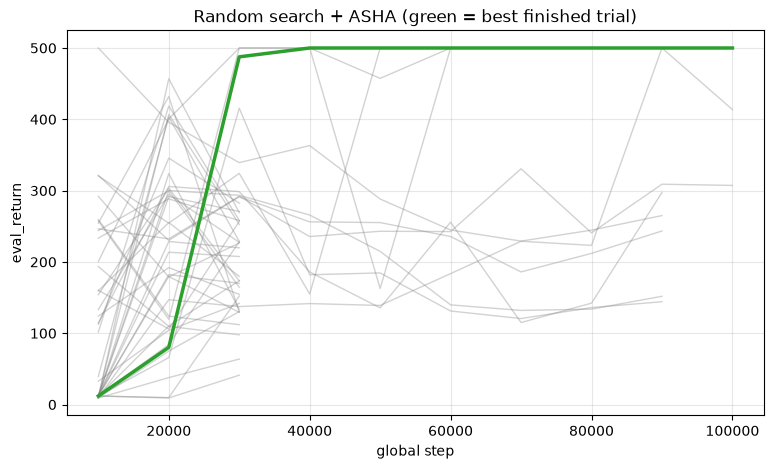

In [45]:
plot_curves(results_random, "Random search + ASHA")

The gray lines that stop at 30k or 90k are the trials ASHA terminated.
That early stopping is where most of the compute saving comes from.

## 5. Experiment 2: Optuna's TPE inside Ray Tune

Ray Tune can use other libraries as its **search algorithm**. Here `OptunaSearch` makes Ray ask Optuna's TPE sampler
for each new configuration, while Ray still handles parallel execution and ASHA still handles early stopping.

TPE learns from finished trials. If 40 trials ran at once, it would have nothing to learn from, so
`ConcurrencyLimiter` keeps only a few trials in flight. That trades some parallelism for smarter suggestions.
We also seed the search with the default configuration through `points_to_evaluate`.

In [46]:
defaults_point = {k: getattr(BASE_ARGS, k) for k in search_space if k not in ("total_timesteps", "seed")}

optuna_search = ConcurrencyLimiter(
    OptunaSearch(sampler=optuna.samplers.TPESampler(seed=42), points_to_evaluate=[defaults_point]),
    max_concurrent=min(4, N_CPUS),
)

tuner = tune.Tuner(
    trainable,
    param_space=search_space,
    tune_config=tune.TuneConfig(metric="eval_return", mode="max", search_alg=optuna_search,
                                scheduler=ASHAScheduler(time_attr="global_step", max_t=TRIAL_STEPS,
                                                        grace_period=30_000, reduction_factor=3),
                                num_samples=NUM_SAMPLES),
    run_config=tune.RunConfig(name="dqn_optuna_asha", storage_path=STORAGE_PATH),
)
t0 = time.time()
results_optuna = tuner.fit()
print(f"finished in {(time.time() - t0) / 60:.1f} min")
describe(results_optuna, "Optuna TPE + ASHA")

2026-10-15 10:22:55,081	INFO tune.py:1007 -- Wrote the latest version of all result files and experiment state to '/Users/harvindersingh/rl/ray_results/dqn_optuna_asha' in 0.0130s.
2026-10-15 10:22:55,084	INFO tune.py:1039 -- Total run time: 144.42 seconds (144.38 seconds for the tuning loop).


finished in 2.4 min
Optuna TPE + ASHA: 40 trials | 11 ran the full budget | 0 errors
best config: {'learning_rate': 0.00018095073787215783, 'batch_size': 128, 'buffer_size': 100000, 'target_network_frequency': 100, 'gamma': 0.995, 'exploration_fraction': 0.4551881257234987, 'end_e': 0.06697913115459413, 'learning_starts': 10000, 'train_frequency': 1}


,eval_return,train_return,global_step,learning_rate,batch_size,buffer_size,target_network_frequency,gamma,exploration_fraction,end_e,learning_starts,train_frequency
0,500.00,500.00,100000,0.000181,128,100000,100,0.995,0.455188,0.066979,10000,1
1,500.00,500.00,100000,0.000117,128,100000,100,0.995,0.348909,0.037480,10000,1
2,500.00,477.20,100000,0.000378,128,100000,100,0.995,0.441374,0.078956,10000,1
3,500.00,422.30,100000,0.000183,32,100000,100,0.995,0.470386,0.057686,10000,1
4,500.00,500.00,100000,0.000140,128,100000,100,0.995,0.399062,0.028092,1000,1
5,500.00,500.00,100000,0.000368,32,100000,100,0.995,0.465612,0.082472,10000,1
6,500.00,434.75,100000,0.000156,128,50000,100,0.995,0.419317,0.065631,10000,1
7,500.00,478.20,100000,0.000176,32,100000,100,0.995,0.444975,0.049997,10000,1
8,323.45,334.45,100000,0.000250,128,10000,500,0.990,0.500000,0.050000,10000,10
9,313.80,411.25,100000,0.000427,64,10000,250,0.980,0.273762,0.037079,10000,1


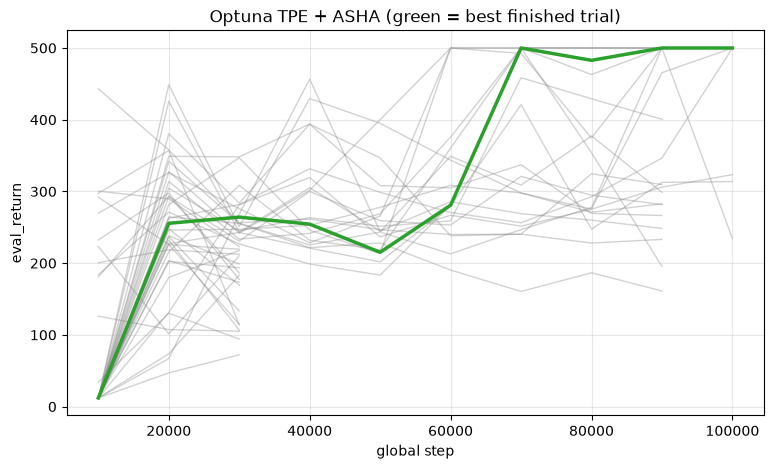

In [47]:
plot_curves(results_optuna, "Optuna TPE + ASHA")

## 6. Experiment 3: Population Based Training (PBT)

ASHA and TPE look for one **fixed** configuration. PBT (Jaderberg et al., 2017) instead trains a **population** of
agents at the same time. Every `perturbation_interval` steps:

1. **Exploit:** each agent in the bottom 25% copies the *checkpoint* of an agent in the top 25%: its network,
   optimizer, replay buffer and step count.
2. **Explore:** the copied hyperparameters are **mutated**. Numbers are multiplied by 0.8 or 1.2, list values move
   to a neighbor, and with probability `resample_probability` a value is drawn fresh from the distribution.

The result is a hyperparameter **schedule** (for example, a high learning rate early and a lower one later)
found within roughly the cost of a single training run per population member.

Some details:
- PBT can only copy agents that have checkpoints, hence `checkpointing=True` below.
- Only hyperparameters that make sense to change mid-run are mutated. `buffer_size` is fixed, because the copied
  replay buffer has a fixed size, and so are `learning_starts` and the exploration schedule.
- `perturbation_interval` should be a multiple of `REPORT_EVERY`, because decisions happen at report time.

In [50]:
POPULATION = 8
PERTURBATION_INTERVAL = 20_000       # each member trains this long (with copying, the "lineage" of the best member is what counts)

pbt_space = {
    "time_attr":"global_step",
    "perturbation_interval": PERTURBATION_INTERVAL,
    # fixed during the run
    "buffer_size": 50_000,
    "learning_starts": 5_000,
    "exploration_fraction": 0.25,
    "end_e": 0.05,
    # initial values, mutated by PBT
    "learning_rate": tune.loguniform(1e-4, 3e-3),
    "batch_size": tune.choice([32, 64, 128, 256]),
    "target_network_frequency": tune.choice([100, 250, 500, 1000, 2000]),
    "train_frequency": tune.choice([1, 4, 10]),
    "gamma": tune.choice([0.95, 0.98, 0.99, 0.995]),
}

pbt = PopulationBasedTraining(
    time_attr="global_step",
    perturbation_interval=20_000,
    quantile_fraction=0.25,
    resample_probability=0.25,
    hyperparam_mutations={      # only these change during training
        "learning_rate": tune.loguniform(1e-4, 3e-3),
        "batch_size": [32, 64, 128, 256],
        "target_network_frequency": [100, 250, 500, 1000, 2000],
        "train_frequency": [1, 4, 10],
        "gamma": [0.95, 0.98, 0.99, 0.995],
    },
)

tuner = tune.Tuner(
    tune.with_resources(tune.with_parameters(dqn_trainable, checkpoint_every=PERTURBATION_INTERVAL), {"cpu": 1}),
    param_space=pbt_space,
    tune_config=tune.TuneConfig(metric="eval_return", mode="max", scheduler=pbt, num_samples=POPULATION),
    run_config=tune.RunConfig(name="dqn_pbt_v2", storage_path=STORAGE_PATH),   # no num_to_keep: keep all checkpoints
)
t0 = time.time()
results_pbt = tuner.fit()
print(f"finished in {(time.time() - t0) / 60:.1f} min")

(dqn_trainable pid=59953) Checkpoint successfully created at: Checkpoint(filesystem=local, path=/Users/harvindersingh/rl/ray_results/dqn_pbt_v2/dqn_trainable_3829e_00003_3_batch_size=64,gamma=0.9950,learning_rate=0.0014,target_network_frequency=250,train_frequency=10_2026-10-15_10-27-11/checkpoint_000000)
2026-10-15 10:27:17,715	INFO pbt.py:741 -- [pbt]: no checkpoint for trial dqn_trainable_3829e_00003. Skip exploit for Trial dqn_trainable_3829e_00006
2026-10-15 10:27:18,074	INFO pbt.py:741 -- [pbt]: no checkpoint for trial dqn_trainable_3829e_00003. Skip exploit for Trial dqn_trainable_3829e_00007
2026-10-15 10:27:19,440	INFO pbt.py:741 -- [pbt]: no checkpoint for trial dqn_trainable_3829e_00002. Skip exploit for Trial dqn_trainable_3829e_00006
2026-10-15 10:27:20,260	INFO pbt.py:903 -- 

[PopulationBasedTraining] [Exploit] Cloning trial 3829e_00002 (score = 318.400000) into trial 3829e_00007 (score = 241.800000)

2026-10-15 10:27:20,261	INFO pbt.py:930 -- 

[PopulationBasedTraining]

finished in 1.4 min


In [51]:
print("errors:", results_pbt.num_errors)  

errors: 0


*** SIGTERM received at time=1792053164 ***
PC: @        0x18c2fffc4  (unknown)  kevent
    @        0x129604cfc  (unknown)  absl::lts_20230802::AbslFailureSignalHandler()
    @        0x18c347744  (unknown)  _sigtramp
    @        0x100cf0b40  (unknown)  select_kqueue_control_impl
    @        0x10068c7c0  (unknown)  _PyEval_EvalFrameDefault
    @        0x100658c84  (unknown)  _PyEval_Vector
    @        0x100658a28  (unknown)  PyEval_EvalCode
    @        0x100653a14  (unknown)  builtin_exec
    @        0x1005a1960  (unknown)  cfunction_vectorcall_FASTCALL_KEYWORDS
    @        0x100688e14  (unknown)  _PyEval_EvalFrameDefault
    @        0x10053ca90  (unknown)  _PyFunction_Vectorcall
    @        0x100714370  (unknown)  pymain_run_module
    @        0x100713dfc  (unknown)  Py_RunMain
    @        0x1004d27f4  (unknown)  main
    @        0x18bf7fe00  (unknown)  start
[2026-10-15 10:32:44,452 E 11272 27198844] logging.cc:474: *** SIGTERM received at time=1792053164 ***
[2026-10-15

In [ ]:
best_pbt = results_pbt.get_best_result(metric="eval_return", mode="max", scope="last")
df_best = best_pbt.metrics_dataframe
print("final eval return of best member:", best_pbt.metrics["eval_return"])
MUTATED = ["learning_rate", "batch_size", "target_network_frequency", "train_frequency", "gamma"]
print("final hyperparameters of best member:", {k: best_pbt.config[k] for k in MUTATED})

fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
for r in results_pbt:
    df = r.metrics_dataframe
    best = r.path == best_pbt.path
    kw = dict(color="tab:green" if best else "tab:gray", alpha=1 if best else .4, lw=2.5 if best else 1)
    ax[0].plot(df["global_step"], df["eval_return"], **kw)
    ax[1].plot(df["global_step"], df["learning_rate"], drawstyle="steps-post", **kw)
    ax[2].plot(df["global_step"], df["target_network_frequency"], drawstyle="steps-post", **kw)
ax[0].set(title="eval return", xlabel="global step")
ax[1].set(title="learning rate schedule", xlabel="global step", yscale="log")
ax[2].set(title="target network frequency", xlabel="global step")
fig.suptitle("PBT population (green = best member's lineage)"); plt.tight_layout(); plt.show()

**Reading the PBT plots:** the jumps in the hyperparameter curves are the moments a member was replaced by a mutated
copy of a better one. The step pattern of the best member *is* the schedule PBT discovered.
The PBT paper's key observation was that these schedules often beat any fixed setting.

## 7. Validate the winners on unseen seeds

Every "best" score above is **optimistically biased**: it is the maximum over many noisy runs, all on seed 1000.
So we retrain each candidate on seeds that were never used during tuning, with the same `TRIAL_STEPS` budget.
This also runs as a Ray experiment: `tune.grid_search` runs every combination of candidate and seed in parallel,
with no scheduler, so every run completes.

For PBT we use the **final** hyperparameters of the best member as a fixed configuration. This is only an
approximation, because PBT's real output is a *schedule*. Ray can replay the exact schedule with
`ray.tune.schedulers.PopulationBasedTrainingReplay` if you want the full effect.

In [ ]:
VALIDATION_SEEDS = [7, 8, 9, 10, 11]

candidates = {
    "defaults": {},
    "random+ASHA": best_config(results_random),
    "optuna+ASHA": best_config(results_optuna),
    "PBT final": {k: best_pbt.config[k] for k in pbt_space if k not in ("total_timesteps", "seed")},
}
for name, cfg in candidates.items():
    print(f"{name:<12} {cfg}")


def validation_trainable(config):
    params = dict(candidates[config["candidate"]], seed=config["seed"], total_timesteps=TRIAL_STEPS)
    dqn_trainable(params)


tuner = tune.Tuner(
    tune.with_resources(validation_trainable, {"cpu": 1}),
    param_space={"candidate": tune.grid_search(list(candidates)), "seed": tune.grid_search(VALIDATION_SEEDS)},
    tune_config=tune.TuneConfig(metric="eval_return", mode="max"),
    run_config=tune.RunConfig(name="dqn_validation", storage_path=STORAGE_PATH),
)
results_val = tuner.fit()

In [ ]:
val = results_val.get_dataframe()[["config/candidate", "config/seed", "eval_return"]]
val.columns = ["candidate", "seed", "eval_return"]
summary = (val.groupby("candidate")["eval_return"].agg(["mean", "std", "min", "max"])
              .reindex(candidates.keys()).round(1))
display(summary)

plt.figure(figsize=(8, 4.5))
for i, name in enumerate(candidates):
    scores = val[val.candidate == name]["eval_return"]
    plt.scatter(np.full(len(scores), i) + np.random.uniform(-.08, .08, len(scores)), scores, alpha=.7)
    plt.errorbar(i, scores.mean(), yerr=scores.std(), fmt="k_", markersize=25, capsize=6)
plt.xticks(range(len(candidates)), list(candidates)); plt.ylabel(f"greedy eval return after {TRIAL_STEPS:,} steps")
plt.title(f"Validation on {len(VALIDATION_SEEDS)} unseen seeds (dots = seeds, bar = mean ± std)")
plt.grid(alpha=.3, axis="y"); plt.show()

Look at the **spread**, not just the mean. A configuration that scores 500 on some seeds and 20 on others is fast
but unstable. In RL, a slightly lower mean with a much smaller spread is often the better choice.

## 8. Practical Ray Tune notes

**Resume an interrupted experiment.** Results live in `STORAGE_PATH`, and an experiment can be continued:
```python
tuner = tune.Tuner.restore(os.path.join(STORAGE_PATH, "dqn_random_asha"), trainable=trainable, resume_errored=True)
results_random = tuner.fit()
```

**Load results later without re-running.**
```python
results_random = tune.Tuner.restore(os.path.join(STORAGE_PATH, "dqn_random_asha"), trainable=trainable).get_results()
```

**Monitoring.** With `pip install "ray[default]"`, the Ray dashboard (usually at http://127.0.0.1:8265) shows live
workers, CPU and memory. Tune also writes TensorBoard logs: `tensorboard --logdir ray_results`.

**GPUs.** Use `tune.with_resources(trainable, {"cpu": 1, "gpu": 0.25})` to pack 4 trials on one GPU.
Inside the trainable, move the networks to `"cuda"`. Ray sets `CUDA_VISIBLE_DEVICES` per trial.

**Scaling to a cluster.** Start Ray on several machines (`ray start --head` / `ray start --address=...`),
call `ray.init(address="auto")`, and use shared storage (`storage_path="s3://..."`). The notebook code stays the same.

**Atari.** Swap in the Atari env wrappers and the Nature CNN from the DQN notebook, and give each trial a GPU fraction.
Because each Atari trial is so expensive, **PBT** is usually the most compute-efficient choice there.
It only costs about `POPULATION` training runs in total.

## Ray Tune vs Optuna (from the DQN notebook)

| | Optuna | Ray Tune |
|---|---|---|
| Main strength | smart sequential search (TPE), simple API | parallel and distributed execution, schedulers |
| Parallelism | possible (shared DB storage), manual | built in: cores, GPUs, clusters |
| Early stopping | pruners (Median, Hyperband, ...) | schedulers (ASHA, HyperBand, Median, ...) |
| Change hyperparameters during training | no | **PBT, PB2** |
| Search algorithms | its own (TPE, CMA-ES, ...) | random/grid built in, plus plug-ins: Optuna, HyperOpt, Ax, Nevergrad, ... |
| Overhead | very low | higher (worker processes, checkpointing) |
| Best for | one machine, cheap trials | many cores or GPUs, expensive trials, RL schedules |

They combine well: experiment 2 used Optuna's sampler with Ray's execution and ASHA.

In [ ]:
ray.shutdown()